# 7.1. Остывание стержня

Решаем $u_t=u_{xx}$ на $[0,1]$, температура на обоих концах равна нулю.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded


def step(u, r, theta):
    rhs = u[1:-1] + (1-theta)*r*(u[:-2] - 2*u[1:-1] + u[2:])
    result = np.zeros_like(u)
    if theta == 0:
        result[1:-1] = rhs
    else:
        A = np.zeros((3, len(u)-2))
        A[0, 1:] = -theta*r
        A[1] = 1 + 2*theta*r
        A[2, :-1] = -theta*r
        result[1:-1] = solve_banded((1, 1), A, rhs)
    return result


def heat(N, r, theta, stops, kind="smooth"):
    x = np.arange(N+1)/N
    if kind == "smooth":
        u = np.sin(np.pi*x) + 0.3*np.sin(5*np.pi*x)
    else:
        u = ((x >= 0.4) & (x <= 0.6)).astype(float)
    u[[0, -1]] = 0
    times, values = [0.0], [u.copy()]
    for end in stops:
        while times[-1] < end - 1e-14:
            next_t = min(times[-1] + r/N**2, end)
            u = step(u, (next_t-times[-1])*N**2, theta)
            times.append(next_t)
            values.append(u.copy())
    return x, np.array(times), np.array(values)


def at(data, T):
    x, t, u = data
    return u[np.argmin(abs(t-T))]


def exact(x, t):
    return np.exp(-np.pi**2*t)*np.sin(np.pi*x) + 0.3*np.exp(-25*np.pi**2*t)*np.sin(5*np.pi*x)

## Гладкий профиль

Начальная температура $u_0=\sin(\pi x)+0.3\sin(5\pi x)$.

Берём $r=0.4$: при уменьшении $\Delta x$ вдвое уменьшаем $\Delta t$ вчетверо.
Последний шаг до нужного момента при необходимости сокращаем.

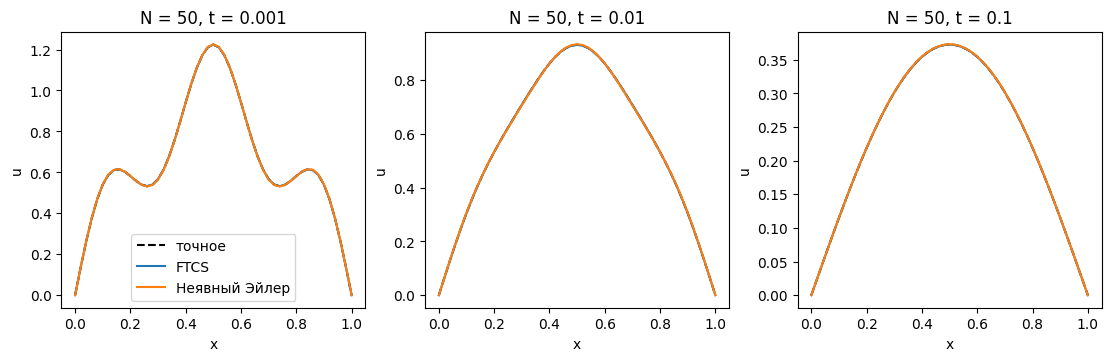

Метод           t       N       E_inf     порядок
FTCS           0.001    25   1.994e-03    —
FTCS           0.001    50   6.477e-04    1.62
FTCS           0.001   100   1.684e-04    1.94
FTCS           0.010    25   2.876e-03    —
FTCS           0.010    50   7.599e-04    1.92
FTCS           0.010   100   1.912e-04    1.99
FTCS           0.100    25   6.738e-04    —
FTCS           0.100    50   1.692e-04    1.99
FTCS           0.100   100   4.236e-05    2.00
Неявный Эйлер  0.001    25   5.023e-03    —
Неявный Эйлер  0.001    50   1.552e-03    1.69
Неявный Эйлер  0.001   100   4.043e-04    1.94
Неявный Эйлер  0.010    25   7.039e-03    —
Неявный Эйлер  0.010    50   1.853e-03    1.93
Неявный Эйлер  0.010   100   4.642e-04    2.00
Неявный Эйлер  0.100    25   1.634e-03    —
Неявный Эйлер  0.100    50   4.109e-04    1.99
Неявный Эйлер  0.100   100   1.028e-04    2.00


In [6]:
times = [0.001, 0.01, 0.1]
methods = {"FTCS": 0, "Неявный Эйлер": 1}
smooth = {(name, N): heat(N, 0.4, theta, times)
          for name, theta in methods.items() for N in [25, 50, 100]}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout="constrained")
for ax, T in zip(axes, times):
    x = smooth["FTCS", 50][0]
    ax.plot(x, exact(x, T), "k--", label="точное")
    for name in methods:
        ax.plot(x, at(smooth[name, 50], T), label=name)
    ax.set(xlabel="x", ylabel="u", title=f"N = 50, t = {T}")
axes[0].legend()
plt.show()

print("Метод           t       N       E_inf     порядок")
for name in methods:
    for T in times:
        previous = None
        for N in [25, 50, 100]:
            d = smooth[name, N]
            error = np.max(abs(at(d, T) - exact(d[0], T)))
            order = "—" if previous is None else f"{np.log2(previous/error):.2f}"
            print(f"{name:14} {T:5.3f}   {N:3d}   {error:.3e}    {order}")
            previous = error


При выбранной связи шагов получаем порядок около двух: ошибка по времени первого порядка
тоже становится порядка $\Delta x^2$.

## Нагретый участок

Теперь $u_0=1$ при $0.4\le x\le0.6$, снаружи — ноль. Пространственная сетка одна: $N=100$.
Для сравнения используем Кранка–Николсона с малым шагом $r=0.02$ на той же сетке.
Это проверка временной ошибки, а не точное решение исходного уравнения.

In [11]:
N = 100
stops = [0.001, 0.002, 0.003, 0.01]
implicit = {"Неявный Эйлер": 1, "Кранк–Николсон": 0.5}
r_values = [0.4, 2, 10]
box = {(name, r): heat(N, r, theta, stops, "box")
       for name, theta in implicit.items() for r in r_values}
reference = heat(N, 0.02, 0.5, stops, "box")
ref_finer = heat(N, 0.01, 0.5, stops, "box")
change = max(np.max(abs(at(reference, T)-at(ref_finer, T))) for T in stops)
print(f"Изменение опорного расчёта при уменьшении шага вдвое: {change:.2e}")

Изменение опорного расчёта при уменьшении шага вдвое: 7.55e-08


Посмотрим первые три слоя Кранка–Николсона при $r=10$ ($\Delta t=0.001$),
включая оба края нагретого участка.

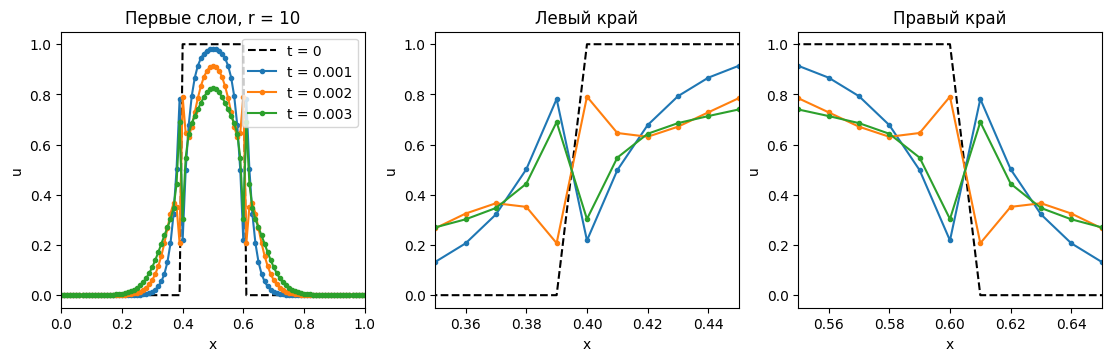

In [12]:
d = box["Кранк–Николсон", 10]
x = d[0]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout="constrained")
for ax, limits in zip(axes, [(0, 1), (0.35, 0.45), (0.55, 0.65)]):
    ax.plot(x, at(d, 0), "k--", label="t = 0")
    for T in stops[:3]:
        ax.plot(x, at(d, T), ".-", label=f"t = {T}")
    ax.set(xlim=limits, ylim=(-0.05, 1.05), xlabel="x", ylabel="u")
axes[0].set_title("Первые слои, r = 10")
axes[1].set_title("Левый край")
axes[2].set_title("Правый край")
axes[0].legend()
plt.show()

Сравним оба метода и разные шаги в одинаковые моменты времени.

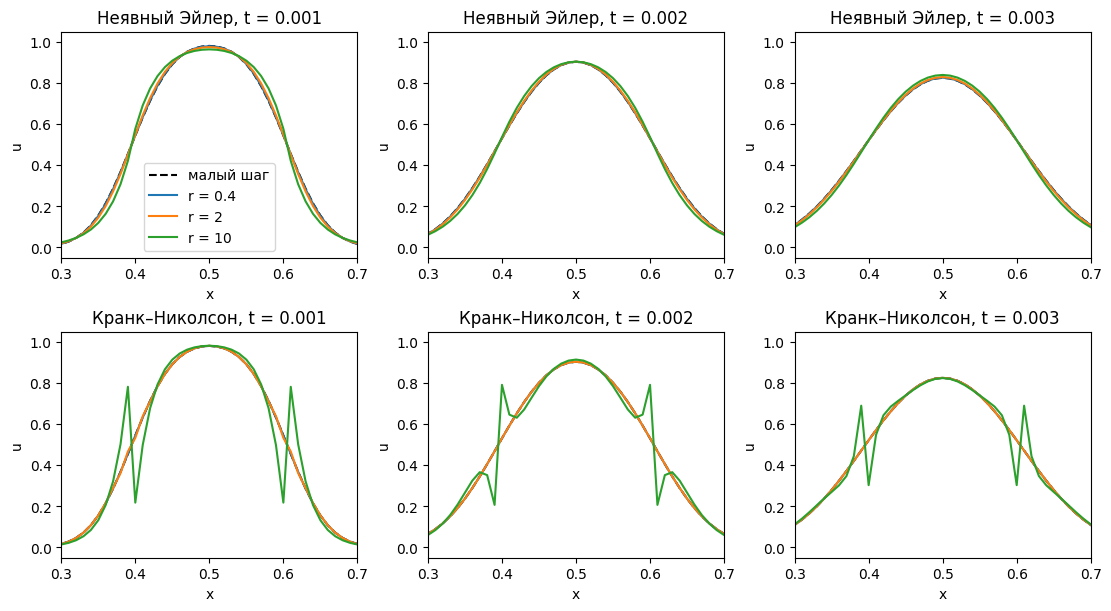

Максимальное отличие от расчёта с малым шагом:
Неявный Эйлер, r = 0.4: t=0.001: 2.79e-03, t=0.002: 1.41e-03, t=0.003: 9.80e-04, t=0.01: 5.52e-04
Неявный Эйлер, r = 2: t=0.001: 1.37e-02, t=0.002: 7.07e-03, t=0.003: 4.91e-03, t=0.01: 2.76e-03
Неявный Эйлер, r = 10: t=0.001: 6.21e-02, t=0.002: 3.46e-02, t=0.003: 2.44e-02, t=0.01: 1.38e-02
Кранк–Николсон, r = 0.4: t=0.001: 4.01e-05, t=0.002: 9.39e-06, t=0.003: 4.05e-06, t=0.01: 7.33e-07
Кранк–Николсон, r = 2: t=0.001: 1.18e-02, t=0.002: 6.54e-04, t=0.003: 1.05e-04, t=0.01: 1.84e-05
Кранк–Николсон, r = 10: t=0.001: 3.27e-01, t=0.002: 2.61e-01, t=0.003: 2.18e-01, t=0.01: 7.84e-02


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
for row, name in enumerate(implicit):
    for col, T in enumerate(stops[:3]):
        ax = axes[row, col]
        ax.plot(x, at(reference, T), "k--", label="малый шаг")
        for r in r_values:
            ax.plot(x, at(box[name, r], T), label=f"r = {r}")
        ax.set(xlim=(0.3, 0.7), ylim=(-0.05, 1.05), xlabel="x", ylabel="u", title=f"{name}, t = {T}")
axes[0, 0].legend()
plt.show()

print("Максимальное отличие от расчёта с малым шагом:")
for name in implicit:
    for r in r_values:
        errors = [np.max(abs(at(box[name, r], T)-at(reference, T))) for T in stops]
        print(f"{name}, r = {r}: " + ", ".join(f"t={T}: {e:.2e}" for T, e in zip(stops, errors)))

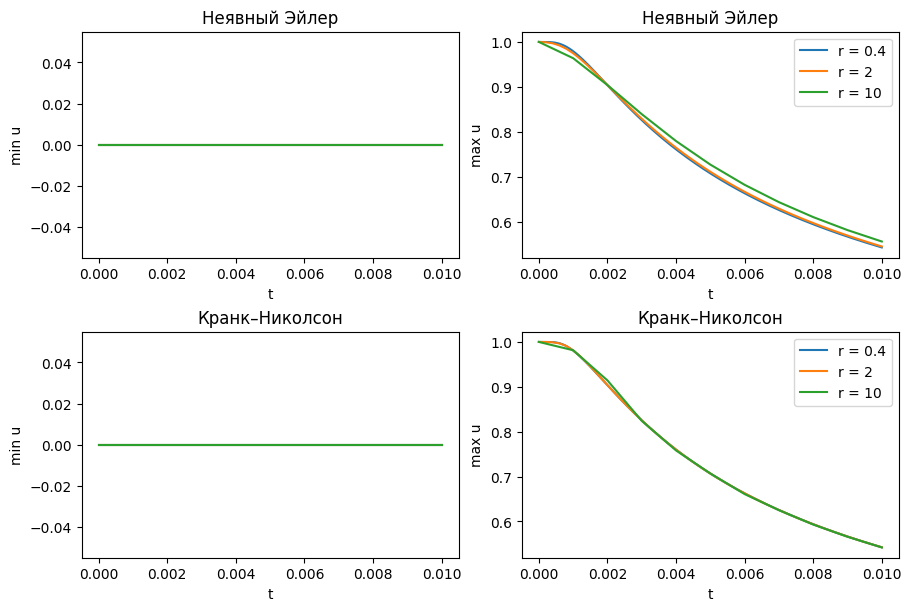

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), layout="constrained")
for row, name in enumerate(implicit):
    for r in r_values:
        x, t, u = box[name, r]
        axes[row, 0].plot(t, u.min(axis=1), label=f"r = {r}")
        axes[row, 1].plot(t, u.max(axis=1), label=f"r = {r}")
    for col, label in enumerate(["min u", "max u"]):
        axes[row, col].set(xlabel="t", ylabel=label, title=name)
    axes[row, 1].legend()
plt.show()

## Вывод

Для FTCS требуется $r\le1/2$; выбранное $r=0.4$ удовлетворяет этому условию.
Неявный Эйлер и Кранк–Николсон для этой задачи безусловно устойчивы: увеличение шага
не вызывает неограниченного роста решения. Но устойчивость не гарантирует точности.

На гладком профиле при сгущении сетки ошибки FTCS и неявного Эйлера уменьшаются,
а оценка порядка приближается к двум. Здесь одновременно уменьшаются оба шага:
$\Delta t=0.4\Delta x^2$.

На разрывном профиле влияние шага особенно заметно. При $t=0.001$ максимальное отличие
Кранка–Николсона от расчёта с малым шагом составляет $4.01\cdot10^{-5}$ при $r=0.4$,
но уже $0.327$ при $r=10$. У неявного Эйлера при $r=10$ это отличие равно $0.0621$.
То есть более высокий порядок схемы сам по себе не обеспечивает лучшего результата
на разрыве при большом шаге. Сравнение выполнено на одной пространственной сетке;
уменьшение шага опорного расчёта вдвое меняет его лишь на $7.55\cdot10^{-8}$.

При $r=10$ Кранк–Николсон даёт осцилляции около обоих краёв нагретого участка:
в профиле появляются лишние локальные максимумы и минимумы. Неявный Эйлер сильнее
сглаживает эти колебания. Отрицательных температур в наших расчётах нет, а общий
минимум равен нулю на границах. Поэтому отсутствие отрицательных значений ещё не
означает отсутствия осцилляций. Для выбора шага нужно проверять и форму профиля,
и отличие от расчёта с меньшим шагом, а не только устойчивость.